# 03 · Failure analysis

**Runtime:** CPU. Needs the outputs of `01_embed` and `02_index_bench`.

**Attribution rule.** For each query, compare precision@10 of
`flat`, `pq64`, `ivf_flat` and `ivf_pq64` (the IVF settings at `LAB2_OPERATING_NPROBE`).

| Pattern | Cause it points to |
|---|---|
| `flat` already ≤ `LAB2_BAD_P` | **embedding model** or **class label** |
| `flat` ≥ `LAB2_GOOD_P`, `ivf_flat` drops by ≥ `LAB2_MIN_DROP` | **approximate index**: the probed lists missed the neighbours |
| `flat` ≥ `LAB2_GOOD_P`, `pq64` or `ivf_pq64` drops by ≥ `LAB2_MIN_DROP` (with `ivf_flat` still good) | **quantization** |

For the embedding-or-label group, the retrieved class names tell the two apart. Visually correct
look-alikes from a sibling class point to the **label**. Visually different images (matched on
background, texture or another object) point to the **embedding model**.

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


## Configuration

In [2]:
def env_str(name, default):
    return os.environ.get(name, default)


def env_int(name, default):
    return int(os.environ.get(name, default))


def env_float(name, default):
    return float(os.environ.get(name, default))


def parse_ids(spec):
    """'0-39' -> [0..39]; '0,3,5' -> [0, 3, 5]; '7' -> [7]."""
    ids = []
    for part in spec.split(","):
        part = part.strip()
        if "-" in part:
            lo, hi = part.split("-")
            ids.extend(range(int(lo), int(hi) + 1))
        elif part:
            ids.append(int(part))
    return ids


LAB2_ROOT = env_str("LAB2_ROOT", "/content/drive/MyDrive/cap6938-hw2")
LAB2_LOCAL_DATA = env_str("LAB2_LOCAL_DATA", "/content/data")      # parquet files here are used before the Hub
LAB2_DATASET = env_str("LAB2_DATASET", "benjamin-paine/imagenet-1k-256x256")
LAB2_NUM_TRAIN_FILES = env_int("LAB2_NUM_TRAIN_FILES", 40)
LAB2_NUM_VAL_FILES = env_int("LAB2_NUM_VAL_FILES", 2)
LAB2_TOPK = env_int("LAB2_TOPK", 10)
LAB2_OPERATING_NPROBE = env_int("LAB2_OPERATING_NPROBE", 16)
LAB2_FAILURES_PER_GROUP = env_int("LAB2_FAILURES_PER_GROUP", 3)
LAB2_GOOD_P = env_float("LAB2_GOOD_P", 0.7)       # precision@10 counted as "good"
LAB2_BAD_P = env_float("LAB2_BAD_P", 0.3)         # precision@10 counted as "bad" for flat
LAB2_MIN_DROP = env_float("LAB2_MIN_DROP", 0.3)   # precision drop that counts as an index/quantization failure
LAB2_THUMB_PX = env_int("LAB2_THUMB_PX", 96)

EMB_DIR, RES_DIR = f"{LAB2_ROOT}/embeddings", f"{LAB2_ROOT}/results"
FIG_DIR = f"{RES_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

## Per-query precision for the four settings

In [3]:
import io, json
from collections import Counter
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from PIL import Image

with open(f"{EMB_DIR}/manifest.json") as f:
    manifest = json.load(f)
with open(f"{EMB_DIR}/class_names.json") as f:
    CLASS_NAMES = json.load(f)
SHARDS = sorted(int(k) for k in manifest["shards"])
OFFSETS = np.array([manifest["shards"][str(i)]["offset"] for i in SHARDS])
db_labels = np.concatenate([np.load(f"{EMB_DIR}/train_{i:02d}_labels.npy") for i in SHARDS]).astype(np.int32)
q_labels = np.load(f"{EMB_DIR}/queries_labels.npy").astype(np.int32)
q_rows = np.load(f"{EMB_DIR}/queries_rows.npy")

op = LAB2_OPERATING_NPROBE
TAGS = {"flat": "flat", "pq64": "pq64", "ivf_flat": f"ivf_flat_nprobe{op}", "ivf_pq64": f"ivf_pq64_nprobe{op}"}
missing = [t for t in TAGS.values() if not os.path.exists(f"{RES_DIR}/topk_{t}.npy")]
assert not missing, f"missing results {missing}; pick LAB2_OPERATING_NPROBE from LAB2_NPROBE_LIST in 02"
TOPK = {name: np.load(f"{RES_DIR}/topk_{tag}.npy") for name, tag in TAGS.items()}


def precision(ids):
    valid = ids >= 0
    same = np.zeros(ids.shape, bool)
    same[valid] = db_labels[ids[valid]] == np.broadcast_to(q_labels[:, None], ids.shape)[valid]
    return same.mean(axis=1)


def short(c):
    return CLASS_NAMES[c].split(",")[0]


P = pd.DataFrame({f"p_{name}": precision(ids) for name, ids in TOPK.items()})
P.insert(0, "query_class", [short(c) for c in q_labels])
print(f"operating nprobe {op}; mean P@10:")
print(P.drop(columns="query_class").mean().round(4).to_string())

operating nprobe 16; mean P@10:
p_flat        0.7012
p_pq64        0.6059
p_ivf_flat    0.7008
p_ivf_pq64    0.6815


## Select failure cases

In [4]:
good, bad, drop = LAB2_GOOD_P, LAB2_BAD_P, LAB2_MIN_DROP
P["drop_index"] = P["p_flat"] - P["p_ivf_flat"]
P["drop_quant"] = np.maximum(P["p_flat"] - P["p_pq64"], P["p_ivf_flat"] - P["p_ivf_pq64"])

groups = {
    "embedding or label": (P[P["p_flat"] <= bad].sort_values("p_flat"), "flat"),
    "approximate index": (P[(P["p_flat"] >= good) & (P["drop_index"] >= drop)]
                          .sort_values("drop_index", ascending=False), "ivf_flat"),
    "quantization": (P[(P["p_flat"] >= good) & (P["p_ivf_flat"] >= good) & (P["drop_quant"] >= drop)]
                     .sort_values("drop_quant", ascending=False), None),
}
cases = []
for group, (rows, setting) in groups.items():
    print(f"{group:>20}: {len(rows):4d} qualifying queries out of {len(P)}")
    for q in rows.index[:LAB2_FAILURES_PER_GROUP]:
        failing = setting or ("pq64" if P.at[q, "p_flat"] - P.at[q, "p_pq64"] >=
                              P.at[q, "p_ivf_flat"] - P.at[q, "p_ivf_pq64"] else "ivf_pq64")
        cases.append((group, int(q), failing))
print(f"{len(cases)} cases selected")
if len(cases) < 5:
    print("Fewer than 5 cases. Report the empty groups as a finding (for example, 'IVF at nprobe "
          f"{op} never drops precision by {drop}') rather than lowering thresholds.")

  embedding or label:  214 qualifying queries out of 1000
   approximate index:    0 qualifying queries out of 1000
        quantization:  130 qualifying queries out of 1000
6 cases selected


## Load the images

Images are read straight from the parquet files on the Hub, one row group at a time, so nothing
close to the full 17.6 GB is downloaded. Any parquet file already in `LAB2_LOCAL_DATA` is used
first. Every fetched database row has its label checked against `db_labels`, which confirms
that the global ids map to the right images.

In [5]:
from huggingface_hub import HfFileSystem

_fs = None
_files = {}
_rowgroups = {}


def parquet_file(name):
    global _fs
    if name not in _files:
        local = os.path.join(LAB2_LOCAL_DATA, name)
        if os.path.exists(local):
            src = local
        else:
            _fs = _fs or HfFileSystem()
            src = _fs.open(f"datasets/{LAB2_DATASET}/{name}", "rb", block_size=8 * 2**20)
        pf = pq.ParquetFile(src)
        sizes = [pf.metadata.row_group(g).num_rows for g in range(pf.num_row_groups)]
        _files[name] = (pf, np.concatenate([[0], np.cumsum(sizes)]))
    return _files[name]


def read_row(name, row):
    pf, bounds = parquet_file(name)
    g = int(np.searchsorted(bounds, row, side="right") - 1)
    if (name, g) not in _rowgroups:
        if len(_rowgroups) > 16:
            _rowgroups.pop(next(iter(_rowgroups)))
        _rowgroups[(name, g)] = pf.read_row_group(g, columns=["image", "label"]).to_pydict()
    t = _rowgroups[(name, g)]
    img = t["image"][row - bounds[g]]
    img = img["bytes"] if isinstance(img, dict) else img
    return Image.open(io.BytesIO(img)).convert("RGB"), t["label"][row - bounds[g]]


def train_image(gid):
    k = int(np.searchsorted(OFFSETS, gid, side="right") - 1)
    name = f"data/train-{SHARDS[k]:05d}-of-{LAB2_NUM_TRAIN_FILES:05d}.parquet"
    img, label = read_row(name, int(gid - OFFSETS[k]))
    assert label == db_labels[gid], f"global id {gid}: parquet label {label} != db label {db_labels[gid]}"
    return img


VAL_FILES = [f"data/validation-{i:05d}-of-{LAB2_NUM_VAL_FILES:05d}.parquet" for i in range(LAB2_NUM_VAL_FILES)]
VAL_OFFSETS = np.concatenate([[0], np.cumsum([parquet_file(n)[0].metadata.num_rows for n in VAL_FILES])])


def query_image(q):
    row = int(q_rows[q])
    k = int(np.searchsorted(VAL_OFFSETS, row, side="right") - 1)
    img, label = read_row(VAL_FILES[k], row - int(VAL_OFFSETS[k]))
    assert label == q_labels[q], f"query {q}: parquet label {label} != {q_labels[q]}"
    return img

## Failure cases

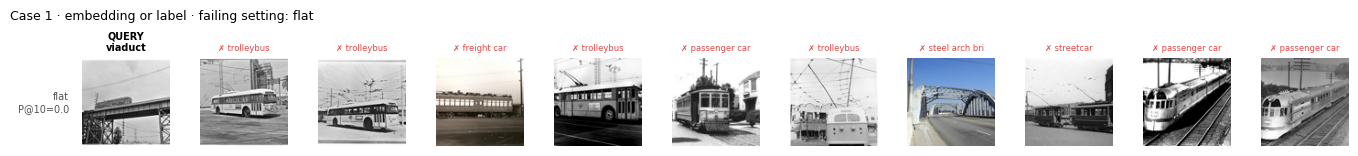

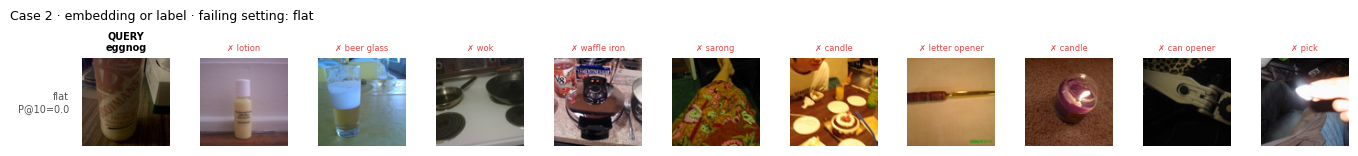

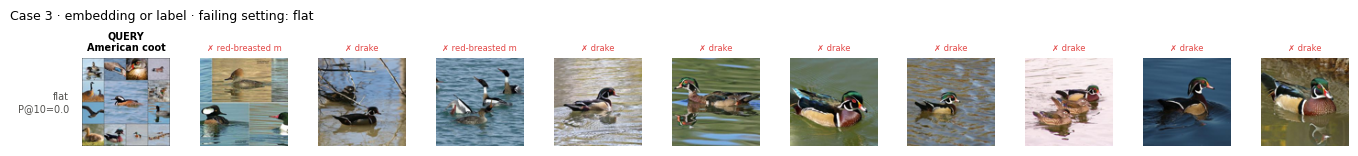

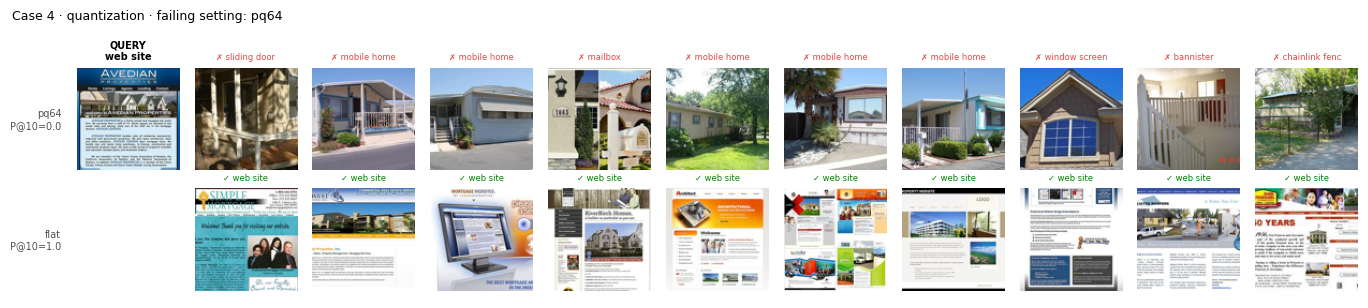

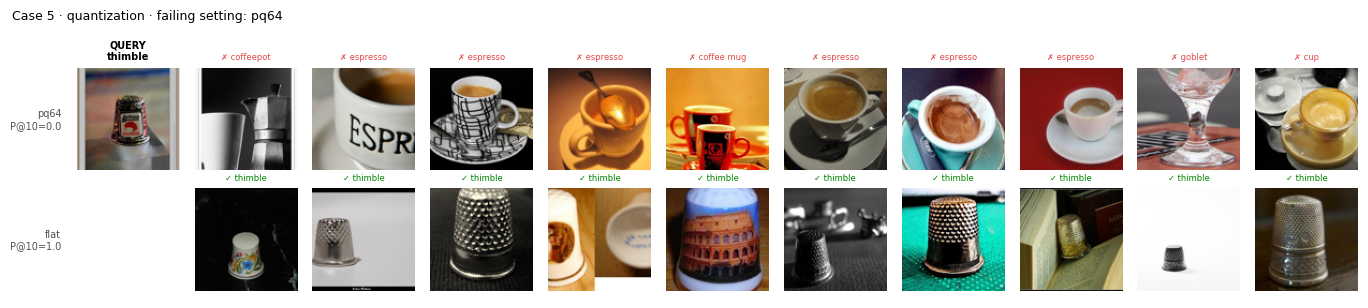

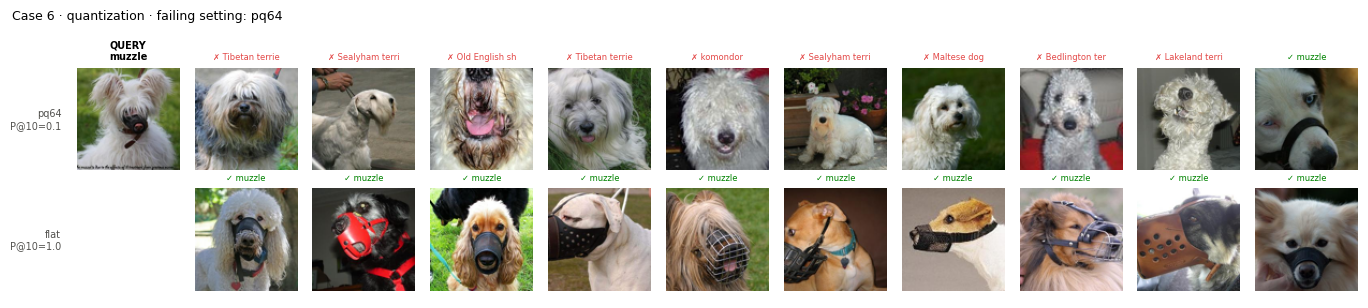

,case,group,query,query_class,failing,p_flat,p_pq64,p_ivf_flat,p_ivf_pq64,most_common_wrong,hint
0,1,embedding or label,3,viaduct,flat,0.0,0.0,0.0,0.0,trolleybus (4/10),scattered classes: check for background/contex...
1,2,embedding or label,12,eggnog,flat,0.0,0.0,0.0,0.0,candle (2/10),scattered classes: check for background/contex...
2,3,embedding or label,20,American coot,flat,0.0,0.1,0.0,0.1,drake (8/10),one sibling class dominates: check for look-al...
3,4,quantization,529,web site,pq64,1.0,0.0,1.0,0.9,mobile home (5/10),
4,5,quantization,877,thimble,pq64,1.0,0.0,1.0,0.9,espresso (6/10),
5,6,quantization,528,muzzle,pq64,1.0,0.1,1.0,1.0,Tibetan terrier (2/10),


In [6]:
OK, BAD, INK_2 = "#008300", "#e34948", "#52514e"


def show_case(n, group, q, failing):
    rows = [failing] if failing == "flat" else [failing, "flat"]
    fig, axes = plt.subplots(len(rows), LAB2_TOPK + 1, figsize=(1.25 * (LAB2_TOPK + 1), 1.55 * len(rows)),
                             squeeze=False)
    thumb = (LAB2_THUMB_PX, LAB2_THUMB_PX)
    for r, setting in enumerate(rows):
        ax = axes[r, 0]
        if r == 0:
            ax.imshow(query_image(q).resize(thumb))
            ax.set_title(f"QUERY\n{short(q_labels[q])[:16]}", fontsize=7, fontweight="bold")
        ax.text(-0.15, 0.5, f"{setting}\nP@10={P.at[q, 'p_' + setting]:.1f}", transform=ax.transAxes,
                ha="right", va="center", fontsize=7, color=INK_2)
        ax.axis("off")
        for k, gid in enumerate(TOPK[setting][q]):
            ax = axes[r, k + 1]
            ax.axis("off")
            if gid < 0:
                continue
            hit = db_labels[gid] == q_labels[q]
            ax.imshow(train_image(int(gid)).resize(thumb))
            ax.set_title(("✓ " if hit else "✗ ") + short(db_labels[gid])[:14], fontsize=6,
                         color=OK if hit else BAD)
    fig.suptitle(f"Case {n} · {group} · failing setting: {failing}", x=0.01, ha="left", fontsize=9)
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/failure_{n:02d}.png", dpi=150, bbox_inches="tight")
    plt.show()


table = []
for n, (group, q, failing) in enumerate(cases, 1):
    show_case(n, group, q, failing)
    wrong = Counter(short(db_labels[g]) for g in TOPK[failing][q] if g >= 0 and db_labels[g] != q_labels[q])
    top_wrong, count = wrong.most_common(1)[0] if wrong else ("-", 0)
    hint = ""
    if group == "embedding or label":
        hint = ("one sibling class dominates: check for look-alike / label ambiguity" if count >= 5
                else "scattered classes: check for background/context or a second object")
    table.append({"case": n, "group": group, "query": q, "query_class": short(q_labels[q]),
                  "failing": failing, **{c: P.at[q, c] for c in ["p_flat", "p_pq64", "p_ivf_flat", "p_ivf_pq64"]},
                  "most_common_wrong": f"{top_wrong} ({count}/{LAB2_TOPK})", "hint": hint})
cases_df = pd.DataFrame(table)
cases_df.to_csv(f"{RES_DIR}/failure_cases.csv", index=False)
display(cases_df)

## Diagnosis

Operating point: nprobe = 16. Cases 1–3 fail even under exact search, so the index and quantization are not to blame; cases 4–6 are correct under exact search and IVF-Flat, so only quantization differs.

| Case | Cause | What went wrong |
|---|---|---|
| 1 · viaduct | Label (multi-object scene) | The black-and-white query shows a streetcar crossing a viaduct. The neighbours are trolleybuses, streetcars and passenger cars in the same old-photo style: the embedding matched the vehicle, which is genuinely in the image. ImageNet gives the picture one label, so a reasonable match counts as wrong. |
| 2 · eggnog | Embedding model | A dim, close-up photo of a bottle. The neighbours (lotion, beer glass, wok, candles) share only the low-light, cluttered indoor look. Eggnog is defined by its contents, not by a distinctive shape, so the model fell back on lighting and setting. |
| 3 · American coot | Label (noisy) | The query is a collage of ducks and mergansers and contains no coot. The neighbours are wood-duck drakes and red-breasted mergansers, which match what the image actually shows. The retrieval is right; the label is wrong. |
| 4 · web site | Quantization | Exact search returns 10/10 web sites. PQ64 returns house exteriors (mobile homes, porches, a mailbox): the compressed code kept the house photo inside the real-estate page and lost the screenshot-and-text layout. IVF-PQ at the same 64 bytes recovers to 0.9. |
| 5 · thimble | Quantization | Exact search returns 10/10 thimbles. PQ64 returns espresso cups, mugs and a coffeepot: compression kept "small cup-shaped object" and dropped the details that separate a thimble from the far more common cups. IVF-PQ recovers to 0.9. |
| 6 · muzzle | Quantization | Exact search returns 10/10 muzzles. PQ64 returns white shaggy terriers: the small muzzle detail was lost and the dominant "fluffy white dog" kept. IVF-PQ recovers to 1.0, because it quantizes the small residual from the IVF centroid instead of the raw vector. |

**Approximate index:** no query qualified at nprobe 16 (0 of 1,000 lost ≥ 0.3 precision to IVF). At this operating point IVF-Flat keeps recall at 0.975 and precision unchanged (0.701), so the index is not a meaningful source of failures.